<a href="https://colab.research.google.com/github/MMKAVERAPPA/4NI23CI052-ML-Lab-2/blob/main/ML_2_Lab_0_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis — Coffee Quality Dataset

This notebook performs Exploratory Data Analysis (EDA) on the **Coffee Quality Data (CQI May-2023)** dataset.

The analysis covers:
1. Loading the dataset using `kagglehub`
2. Initial data inspection
3. Missing-value analysis
4. Data cleaning
5. Summary statistics
6. Distribution plots
7. Outlier analysis using boxplots
8. Categorical-variable distributions
9. Correlation analysis
10. Key observations

## 1. Imports

In [1]:
import kagglehub
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-darkgrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

## 2. Download and Load the Dataset

In [2]:
# Download the Coffee Quality Data (CQI May-2023) dataset from Kaggle
path = kagglehub.dataset_download("fatihb/coffee-quality-data-cqi")

print("Path to dataset files:", path)
print("Files found:", os.listdir(path))

# Locate the CSV file automatically
csv_files = [f for f in os.listdir(path) if f.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError("No CSV file was found in the downloaded dataset.")

print("CSV files:", csv_files)

# Load the first CSV file
csv_path = os.path.join(path, csv_files[0])
df = pd.read_csv(csv_path)

print("Shape:", df.shape)
df.head()

100%|██████████| 21.8k/21.8k [00:00<00:00, 17.7MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/fatihb/coffee-quality-data-cqi/versions/1
Files found: ['df_arabica_clean.csv']
CSV files: ['df_arabica_clean.csv']
Shape: (207, 41)


,Unnamed: 0,ID,Country of Origin,Farm Name,Lot Number,Mill,ICO Number,Company,Altitude,Region,Producer,Number of Bags,Bag Weight,In-Country Partner,Harvest Year,Grading Date,Owner,Variety,Status,Processing Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean Cup,Sweetness,Overall,Defects,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Color,Category Two Defects,Expiration,Certification Body,Certification Address,Certification Contact
0,0,0,Colombia,Finca El Paraiso,CQU2022015,Finca El Paraiso,NaN,Coffee Quality Union,1700-1930,"Piendamo,Cauca",Diego Samuel Bermudez,1,35 kg,Japan Coffee Exchange,2021 / 2022,"September 21st, 2022",Coffee Quality Union,Castillo,Completed,Double Anaerobic Washed,8.58,8.50,8.42,8.58,8.25,8.42,10.0,10.0,10.0,8.58,0.0,89.33,11.8,0,0,green,3,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
1,1,1,Taiwan,Royal Bean Geisha Estate,"The 2022 Pacific Rim Coffee Summit,T037",Royal Bean Geisha Estate,NaN,Taiwan Coffee Laboratory,1200,Chiayi,曾福森,1,80 kg,Taiwan Coffee Laboratory 台灣咖啡研究室,2021 / 2022,"November 15th, 2022",Taiwan Coffee Laboratory 台灣咖啡研究室,Gesha,Completed,Washed / Wet,8.50,8.50,7.92,8.00,7.92,8.25,10.0,10.0,10.0,8.50,0.0,87.58,10.5,0,0,blue-green,0,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
2,2,2,Laos,OKLAO coffee farms,"The 2022 Pacific Rim Coffee Summit,LA01",oklao coffee processing plant,NaN,Taiwan Coffee Laboratory,1300,Laos Borofen Plateau,WU TAO CHI,19,25 kg,Taiwan Coffee Laboratory 台灣咖啡研究室,2021 / 2022,"November 15th, 2022",Taiwan Coffee Laboratory 台灣咖啡研究室,Java,Completed,Semi Washed,8.33,8.42,8.08,8.17,7.92,8.17,10.0,10.0,10.0,8.33,0.0,87.42,10.4,0,0,yellowish,2,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
3,3,3,Costa Rica,La Cumbre,CQU2022017,La Montana Tarrazu MIll,NaN,Coffee Quality Union,1900,"Los Santos,Tarrazu",Santa Maria de Dota,1,22 kg,Japan Coffee Exchange,2022,"September 21st, 2022",Coffee Quality Union,Gesha,Completed,Washed / Wet,8.08,8.17,8.17,8.25,8.17,8.08,10.0,10.0,10.0,8.25,0.0,87.17,11.8,0,0,green,0,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
4,4,4,Colombia,Finca Santuario,CQU2023002,Finca Santuario,NaN,Coffee Quality Union,1850-2100,"Popayan,Cauca",Camilo Merizalde,2,24 kg,Japan Coffee Exchange,2022,"March 6th, 2023",Coffee Quality Union,Red Bourbon,Completed,"Honey,Mossto",8.33,8.33,8.08,8.25,7.92,7.92,10.0,10.0,10.0,8.25,0.0,87.08,11.6,0,2,yellow-green,2,"March 5th, 2024",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901


## 3. Initial Data Inspection

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nFirst five rows:")
display(df.head())

print("\nLast five rows:")
display(df.tail())

print("\nBasic information:")
df.info()

Dataset shape: (207, 41)

Column names:
['Unnamed: 0', 'ID', 'Country of Origin', 'Farm Name', 'Lot Number', 'Mill', 'ICO Number', 'Company', 'Altitude', 'Region', 'Producer', 'Number of Bags', 'Bag Weight', 'In-Country Partner', 'Harvest Year', 'Grading Date', 'Owner', 'Variety', 'Status', 'Processing Method', 'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance', 'Uniformity', 'Clean Cup', 'Sweetness', 'Overall', 'Defects', 'Total Cup Points', 'Moisture Percentage', 'Category One Defects', 'Quakers', 'Color', 'Category Two Defects', 'Expiration', 'Certification Body', 'Certification Address', 'Certification Contact']

Data types:


,dtype
Unnamed: 0,int64
ID,int64
Country of Origin,object
Farm Name,object
Lot Number,object
Mill,object
ICO Number,object
Company,object
Altitude,object
Region,object



First five rows:


,Unnamed: 0,ID,Country of Origin,Farm Name,Lot Number,Mill,ICO Number,Company,Altitude,Region,Producer,Number of Bags,Bag Weight,In-Country Partner,Harvest Year,Grading Date,Owner,Variety,Status,Processing Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean Cup,Sweetness,Overall,Defects,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Color,Category Two Defects,Expiration,Certification Body,Certification Address,Certification Contact
0,0,0,Colombia,Finca El Paraiso,CQU2022015,Finca El Paraiso,NaN,Coffee Quality Union,1700-1930,"Piendamo,Cauca",Diego Samuel Bermudez,1,35 kg,Japan Coffee Exchange,2021 / 2022,"September 21st, 2022",Coffee Quality Union,Castillo,Completed,Double Anaerobic Washed,8.58,8.50,8.42,8.58,8.25,8.42,10.0,10.0,10.0,8.58,0.0,89.33,11.8,0,0,green,3,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
1,1,1,Taiwan,Royal Bean Geisha Estate,"The 2022 Pacific Rim Coffee Summit,T037",Royal Bean Geisha Estate,NaN,Taiwan Coffee Laboratory,1200,Chiayi,曾福森,1,80 kg,Taiwan Coffee Laboratory 台灣咖啡研究室,2021 / 2022,"November 15th, 2022",Taiwan Coffee Laboratory 台灣咖啡研究室,Gesha,Completed,Washed / Wet,8.50,8.50,7.92,8.00,7.92,8.25,10.0,10.0,10.0,8.50,0.0,87.58,10.5,0,0,blue-green,0,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
2,2,2,Laos,OKLAO coffee farms,"The 2022 Pacific Rim Coffee Summit,LA01",oklao coffee processing plant,NaN,Taiwan Coffee Laboratory,1300,Laos Borofen Plateau,WU TAO CHI,19,25 kg,Taiwan Coffee Laboratory 台灣咖啡研究室,2021 / 2022,"November 15th, 2022",Taiwan Coffee Laboratory 台灣咖啡研究室,Java,Completed,Semi Washed,8.33,8.42,8.08,8.17,7.92,8.17,10.0,10.0,10.0,8.33,0.0,87.42,10.4,0,0,yellowish,2,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
3,3,3,Costa Rica,La Cumbre,CQU2022017,La Montana Tarrazu MIll,NaN,Coffee Quality Union,1900,"Los Santos,Tarrazu",Santa Maria de Dota,1,22 kg,Japan Coffee Exchange,2022,"September 21st, 2022",Coffee Quality Union,Gesha,Completed,Washed / Wet,8.08,8.17,8.17,8.25,8.17,8.08,10.0,10.0,10.0,8.25,0.0,87.17,11.8,0,0,green,0,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
4,4,4,Colombia,Finca Santuario,CQU2023002,Finca Santuario,NaN,Coffee Quality Union,1850-2100,"Popayan,Cauca",Camilo Merizalde,2,24 kg,Japan Coffee Exchange,2022,"March 6th, 2023",Coffee Quality Union,Red Bourbon,Completed,"Honey,Mossto",8.33,8.33,8.08,8.25,7.92,7.92,10.0,10.0,10.0,8.25,0.0,87.08,11.6,0,2,yellow-green,2,"March 5th, 2024",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901



Last five rows:


,Unnamed: 0,ID,Country of Origin,Farm Name,Lot Number,Mill,ICO Number,Company,Altitude,Region,Producer,Number of Bags,Bag Weight,In-Country Partner,Harvest Year,Grading Date,Owner,Variety,Status,Processing Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean Cup,Sweetness,Overall,Defects,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Color,Category Two Defects,Expiration,Certification Body,Certification Address,Certification Contact
202,202,202,Brazil,Fazenda Conquista,019/22,Dry Mill,NaN,Ipanema Coffees,950,Sul de Minas,Ipanema Coffees,2240,60 kg,Brazil Specialty Coffee Association,2022 / 2023,"February 2nd, 2023",Ipanema Coffees,Mundo Novo,Completed,Natural / Dry,7.17,7.17,6.92,7.17,7.42,7.17,10.0,10.0,10.0,7.08,0.0,80.08,11.4,0,0,green,4,"February 2nd, 2024",Brazil Specialty Coffee Association,"Rua Gaspar Batista Paiva, 416 – Santa Luiza Va...",Chris Allen - 55 35 3212-4705
203,203,203,Nicaragua,Finca San Felipe,017-053-0155,Beneficio Atlantic Sébaco,017-053-0155,Exportadora Atlantic S.A,1200,Matagalpa,Exportadora Atlantic S.A.,300,30 kg,Asociación de Cafés Especiales de Nicaragua,2022 / 2023,"March 3rd, 2023","Exportadora Atlantic, S.A.",SHG,Completed,Natural / Dry,7.33,7.08,6.75,7.17,7.42,7.17,10.0,10.0,10.0,7.08,0.0,80.00,10.4,0,2,green,12,"March 2nd, 2024",Asociación de Cafés Especiales de Nicaragua,"Del Hotel Seminole 2 C al lago, 1 C arriba.",Maria Ines Benavidez Toval - 011-(505)-8396 4717
204,204,204,Laos,-,105/3/VL7285-005,DRY MILL,105/3/VL7285-005,Marubeni Corporation,1300,Bolaven Plateau,"LAO MINH TIEN COFFEE SOLE CO.,LTD",343,60 kg,Japan Coffee Exchange,2021 / 2022,"November 11th, 2022",Ikuto Uehara,Catimor,Completed,Washed / Wet,7.25,7.17,7.08,7.00,7.08,7.08,10.0,10.0,10.0,7.00,0.0,79.67,11.6,0,9,green,11,"November 11th, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
205,205,205,El Salvador,"Rosario de Maria II, Area de La Pila",0423A01,"Optimum Coffee, San Salvador, El Salvador",NaN,Aprentium Enterprises LLC,1200,"Volcan de San Vicente, La Paz, El Salvador",Roselia Yglesias,1,2 kg,Salvadoran Coffee Council,2023,"March 8th, 2023",Roselia Yglesias,Maragogype,Completed,Natural / Dry,6.50,6.75,6.75,7.17,7.08,7.00,10.0,10.0,10.0,6.83,0.0,78.08,11.0,0,12,bluish-green,13,"March 7th, 2024",Salvadoran Coffee Council,"Final 1a. Av. Norte y 13 Calle Pte., dentro de...",Tomas Bonilla - (503) 2505-6600
206,206,206,Brazil,Walter Matter,1058 y 1059,Beneficio humedo/seco,002/1208/1016,Descafeinadores Mexicano SA. de CV,850-1100,Minas Gerais,Walter Matter,600,60 kg,Centro Agroecológico del Café A.C.,2021 / 2022,"November 18th, 2022",Descafeinadores Mexicanos S.A de C.V,Mundo Novo,Completed,SEMI-LAVADO,7.25,7.08,6.67,6.83,6.83,6.67,10.0,10.0,10.0,6.67,0.0,78.00,11.3,0,0,green,1,"November 18th, 2023",Centro Agroecológico del Café A.C.,"Instituto de Ecología A. C., Campus III Edific...",Stephany Escamilla Femat - Tel. +52 228 842180...



Basic information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             207 non-null    int64  
 1   ID                     207 non-null    int64  
 2   Country of Origin      207 non-null    object 
 3   Farm Name              205 non-null    object 
 4   Lot Number             206 non-null    object 
 5   Mill                   204 non-null    object 
 6   ICO Number             75 non-null     object 
 7   Company                207 non-null    object 
 8   Altitude               206 non-null    object 
 9   Region                 205 non-null    object 
 10  Producer               206 non-null    object 
 11  Number of Bags         207 non-null    int64  
 12  Bag Weight             207 non-null    object 
 13  In-Country Partner     207 non-null    object 
 14  Harvest Year           207 non-null   

## 4. Missing-Value Analysis

In [4]:
# Count missing values per column
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct
}).sort_values("missing_pct", ascending=False)

display(missing_df)

,missing_count,missing_pct
ICO Number,132,63.768116
Variety,6,2.898551
Processing Method,5,2.415459
Mill,3,1.449275
Farm Name,2,0.966184
Region,2,0.966184
Producer,1,0.483092
Altitude,1,0.483092
Lot Number,1,0.483092
Company,0,0.000000


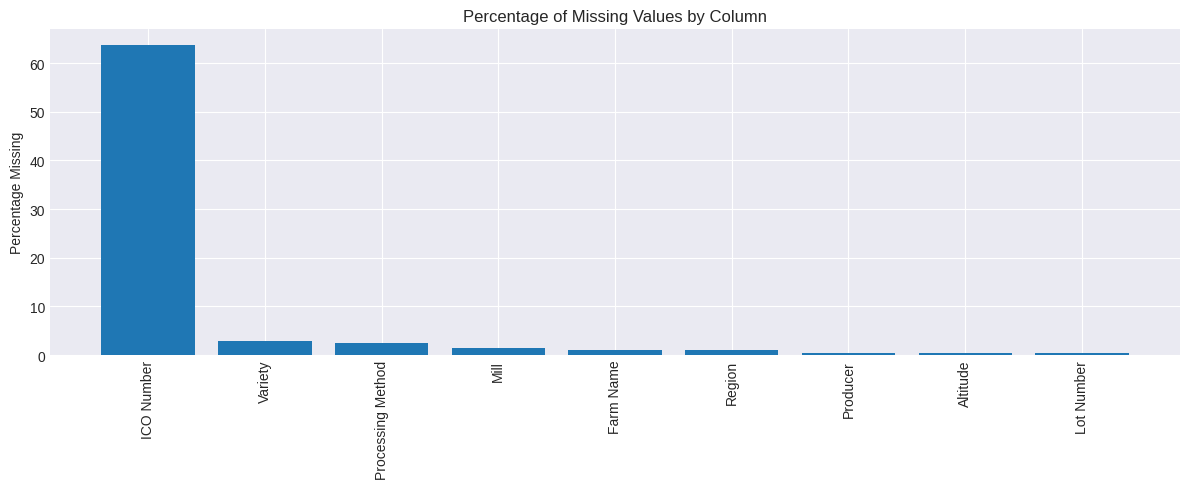

In [5]:
# Visualize missing values only when missing data exists
missing_nonzero = missing_df[missing_df["missing_count"] > 0]

if len(missing_nonzero) > 0:
    plt.figure(figsize=(12, 5))
    plt.bar(missing_nonzero.index.astype(str), missing_nonzero["missing_pct"])
    plt.xticks(rotation=90)
    plt.ylabel("Percentage Missing")
    plt.title("Percentage of Missing Values by Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset.")

## 5. Data Cleaning

In [6]:
# Work on a copy so the original dataframe remains unchanged
df_clean = df.copy()

# Remove completely empty rows/columns
df_clean = df_clean.dropna(axis=0, how="all")
df_clean = df_clean.dropna(axis=1, how="all")

# Remove duplicate rows
duplicate_count = df_clean.duplicated().sum()
print("Duplicate rows found:", duplicate_count)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df_clean.shape)

Duplicate rows found: 0
Shape after removing duplicates: (207, 41)


In [7]:
# Convert columns that are numeric but stored as text when possible.
# This is deliberately conservative so categorical text is not damaged.
for col in df_clean.columns:
    if df_clean[col].dtype == "object":
        converted = pd.to_numeric(df_clean[col], errors="coerce")
        non_missing_original = df_clean[col].notna().sum()

        if non_missing_original > 0:
            conversion_rate = converted.notna().sum() / non_missing_original
            if conversion_rate >= 0.90:
                df_clean[col] = converted

# Separate numeric and categorical columns
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df_clean.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numeric columns:", numeric_cols)
print("\nCategorical columns:", categorical_cols)

Numeric columns: ['Unnamed: 0', 'ID', 'Number of Bags', 'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance', 'Uniformity', 'Clean Cup', 'Sweetness', 'Overall', 'Defects', 'Total Cup Points', 'Moisture Percentage', 'Category One Defects', 'Quakers', 'Category Two Defects']

Categorical columns: ['Country of Origin', 'Farm Name', 'Lot Number', 'Mill', 'ICO Number', 'Company', 'Altitude', 'Region', 'Producer', 'Bag Weight', 'In-Country Partner', 'Harvest Year', 'Grading Date', 'Owner', 'Variety', 'Status', 'Processing Method', 'Color', 'Expiration', 'Certification Body', 'Certification Address', 'Certification Contact']


In [8]:
# Fill missing values using a simple, reproducible strategy:
# - numerical columns -> median
# - categorical columns -> mode
for col in numeric_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in categorical_cols:
    if df_clean[col].isnull().any():
        mode = df_clean[col].mode()
        if not mode.empty:
            df_clean[col] = df_clean[col].fillna(mode.iloc[0])

print("Remaining missing values:", int(df_clean.isnull().sum().sum()))
display(df_clean.head())

Remaining missing values: 0


,Unnamed: 0,ID,Country of Origin,Farm Name,Lot Number,Mill,ICO Number,Company,Altitude,Region,Producer,Number of Bags,Bag Weight,In-Country Partner,Harvest Year,Grading Date,Owner,Variety,Status,Processing Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean Cup,Sweetness,Overall,Defects,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Color,Category Two Defects,Expiration,Certification Body,Certification Address,Certification Contact
0,0,0,Colombia,Finca El Paraiso,CQU2022015,Finca El Paraiso,non,Coffee Quality Union,1700-1930,"Piendamo,Cauca",Diego Samuel Bermudez,1,35 kg,Japan Coffee Exchange,2021 / 2022,"September 21st, 2022",Coffee Quality Union,Castillo,Completed,Double Anaerobic Washed,8.58,8.50,8.42,8.58,8.25,8.42,10.0,10.0,10.0,8.58,0.0,89.33,11.8,0,0,green,3,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
1,1,1,Taiwan,Royal Bean Geisha Estate,"The 2022 Pacific Rim Coffee Summit,T037",Royal Bean Geisha Estate,non,Taiwan Coffee Laboratory,1200,Chiayi,曾福森,1,80 kg,Taiwan Coffee Laboratory 台灣咖啡研究室,2021 / 2022,"November 15th, 2022",Taiwan Coffee Laboratory 台灣咖啡研究室,Gesha,Completed,Washed / Wet,8.50,8.50,7.92,8.00,7.92,8.25,10.0,10.0,10.0,8.50,0.0,87.58,10.5,0,0,blue-green,0,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
2,2,2,Laos,OKLAO coffee farms,"The 2022 Pacific Rim Coffee Summit,LA01",oklao coffee processing plant,non,Taiwan Coffee Laboratory,1300,Laos Borofen Plateau,WU TAO CHI,19,25 kg,Taiwan Coffee Laboratory 台灣咖啡研究室,2021 / 2022,"November 15th, 2022",Taiwan Coffee Laboratory 台灣咖啡研究室,Java,Completed,Semi Washed,8.33,8.42,8.08,8.17,7.92,8.17,10.0,10.0,10.0,8.33,0.0,87.42,10.4,0,0,yellowish,2,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
3,3,3,Costa Rica,La Cumbre,CQU2022017,La Montana Tarrazu MIll,non,Coffee Quality Union,1900,"Los Santos,Tarrazu",Santa Maria de Dota,1,22 kg,Japan Coffee Exchange,2022,"September 21st, 2022",Coffee Quality Union,Gesha,Completed,Washed / Wet,8.08,8.17,8.17,8.25,8.17,8.08,10.0,10.0,10.0,8.25,0.0,87.17,11.8,0,0,green,0,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
4,4,4,Colombia,Finca Santuario,CQU2023002,Finca Santuario,non,Coffee Quality Union,1850-2100,"Popayan,Cauca",Camilo Merizalde,2,24 kg,Japan Coffee Exchange,2022,"March 6th, 2023",Coffee Quality Union,Red Bourbon,Completed,"Honey,Mossto",8.33,8.33,8.08,8.25,7.92,7.92,10.0,10.0,10.0,8.25,0.0,87.08,11.6,0,2,yellow-green,2,"March 5th, 2024",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901


## 6. Summary Statistics

In [9]:
print("Numerical summary statistics:")
display(df_clean[numeric_cols].describe().T)

Numerical summary statistics:


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,207.0,103.000000,59.899917,0.00,51.50,103.00,154.500,206.00
ID,207.0,103.000000,59.899917,0.00,51.50,103.00,154.500,206.00
Number of Bags,207.0,155.449275,244.484868,1.00,1.00,14.00,275.000,2240.00
Aroma,207.0,7.721063,0.287626,6.50,7.58,7.67,7.920,8.58
Flavor,207.0,7.744734,0.279613,6.75,7.58,7.75,7.920,8.50
Aftertaste,207.0,7.599758,0.275911,6.67,7.42,7.58,7.750,8.42
Acidity,207.0,7.690290,0.259510,6.83,7.50,7.67,7.875,8.58
Body,207.0,7.640918,0.233499,6.83,7.50,7.67,7.750,8.25
Balance,207.0,7.644058,0.256299,6.67,7.50,7.67,7.790,8.42
Uniformity,207.0,9.990338,0.103306,8.67,10.00,10.00,10.000,10.00


In [10]:
if categorical_cols:
    print("Categorical summary statistics:")
    display(df_clean[categorical_cols].describe().T)
else:
    print("No categorical columns remain.")

Categorical summary statistics:


,count,unique,top,freq
Country of Origin,207,22,Taiwan,61
Farm Name,207,172,Doi Tung Development Project,9
Lot Number,207,187,1,12
Mill,207,162,Dry Mill,14
ICO Number,207,67,non,137
Company,207,72,Taiwan Coffee Laboratory,51
Altitude,207,97,1200,24
Region,207,120,Chiayi,14
Producer,207,172,Doi Tung Development Project,8
Bag Weight,207,39,30 kg,39


## 7. Distribution Plots

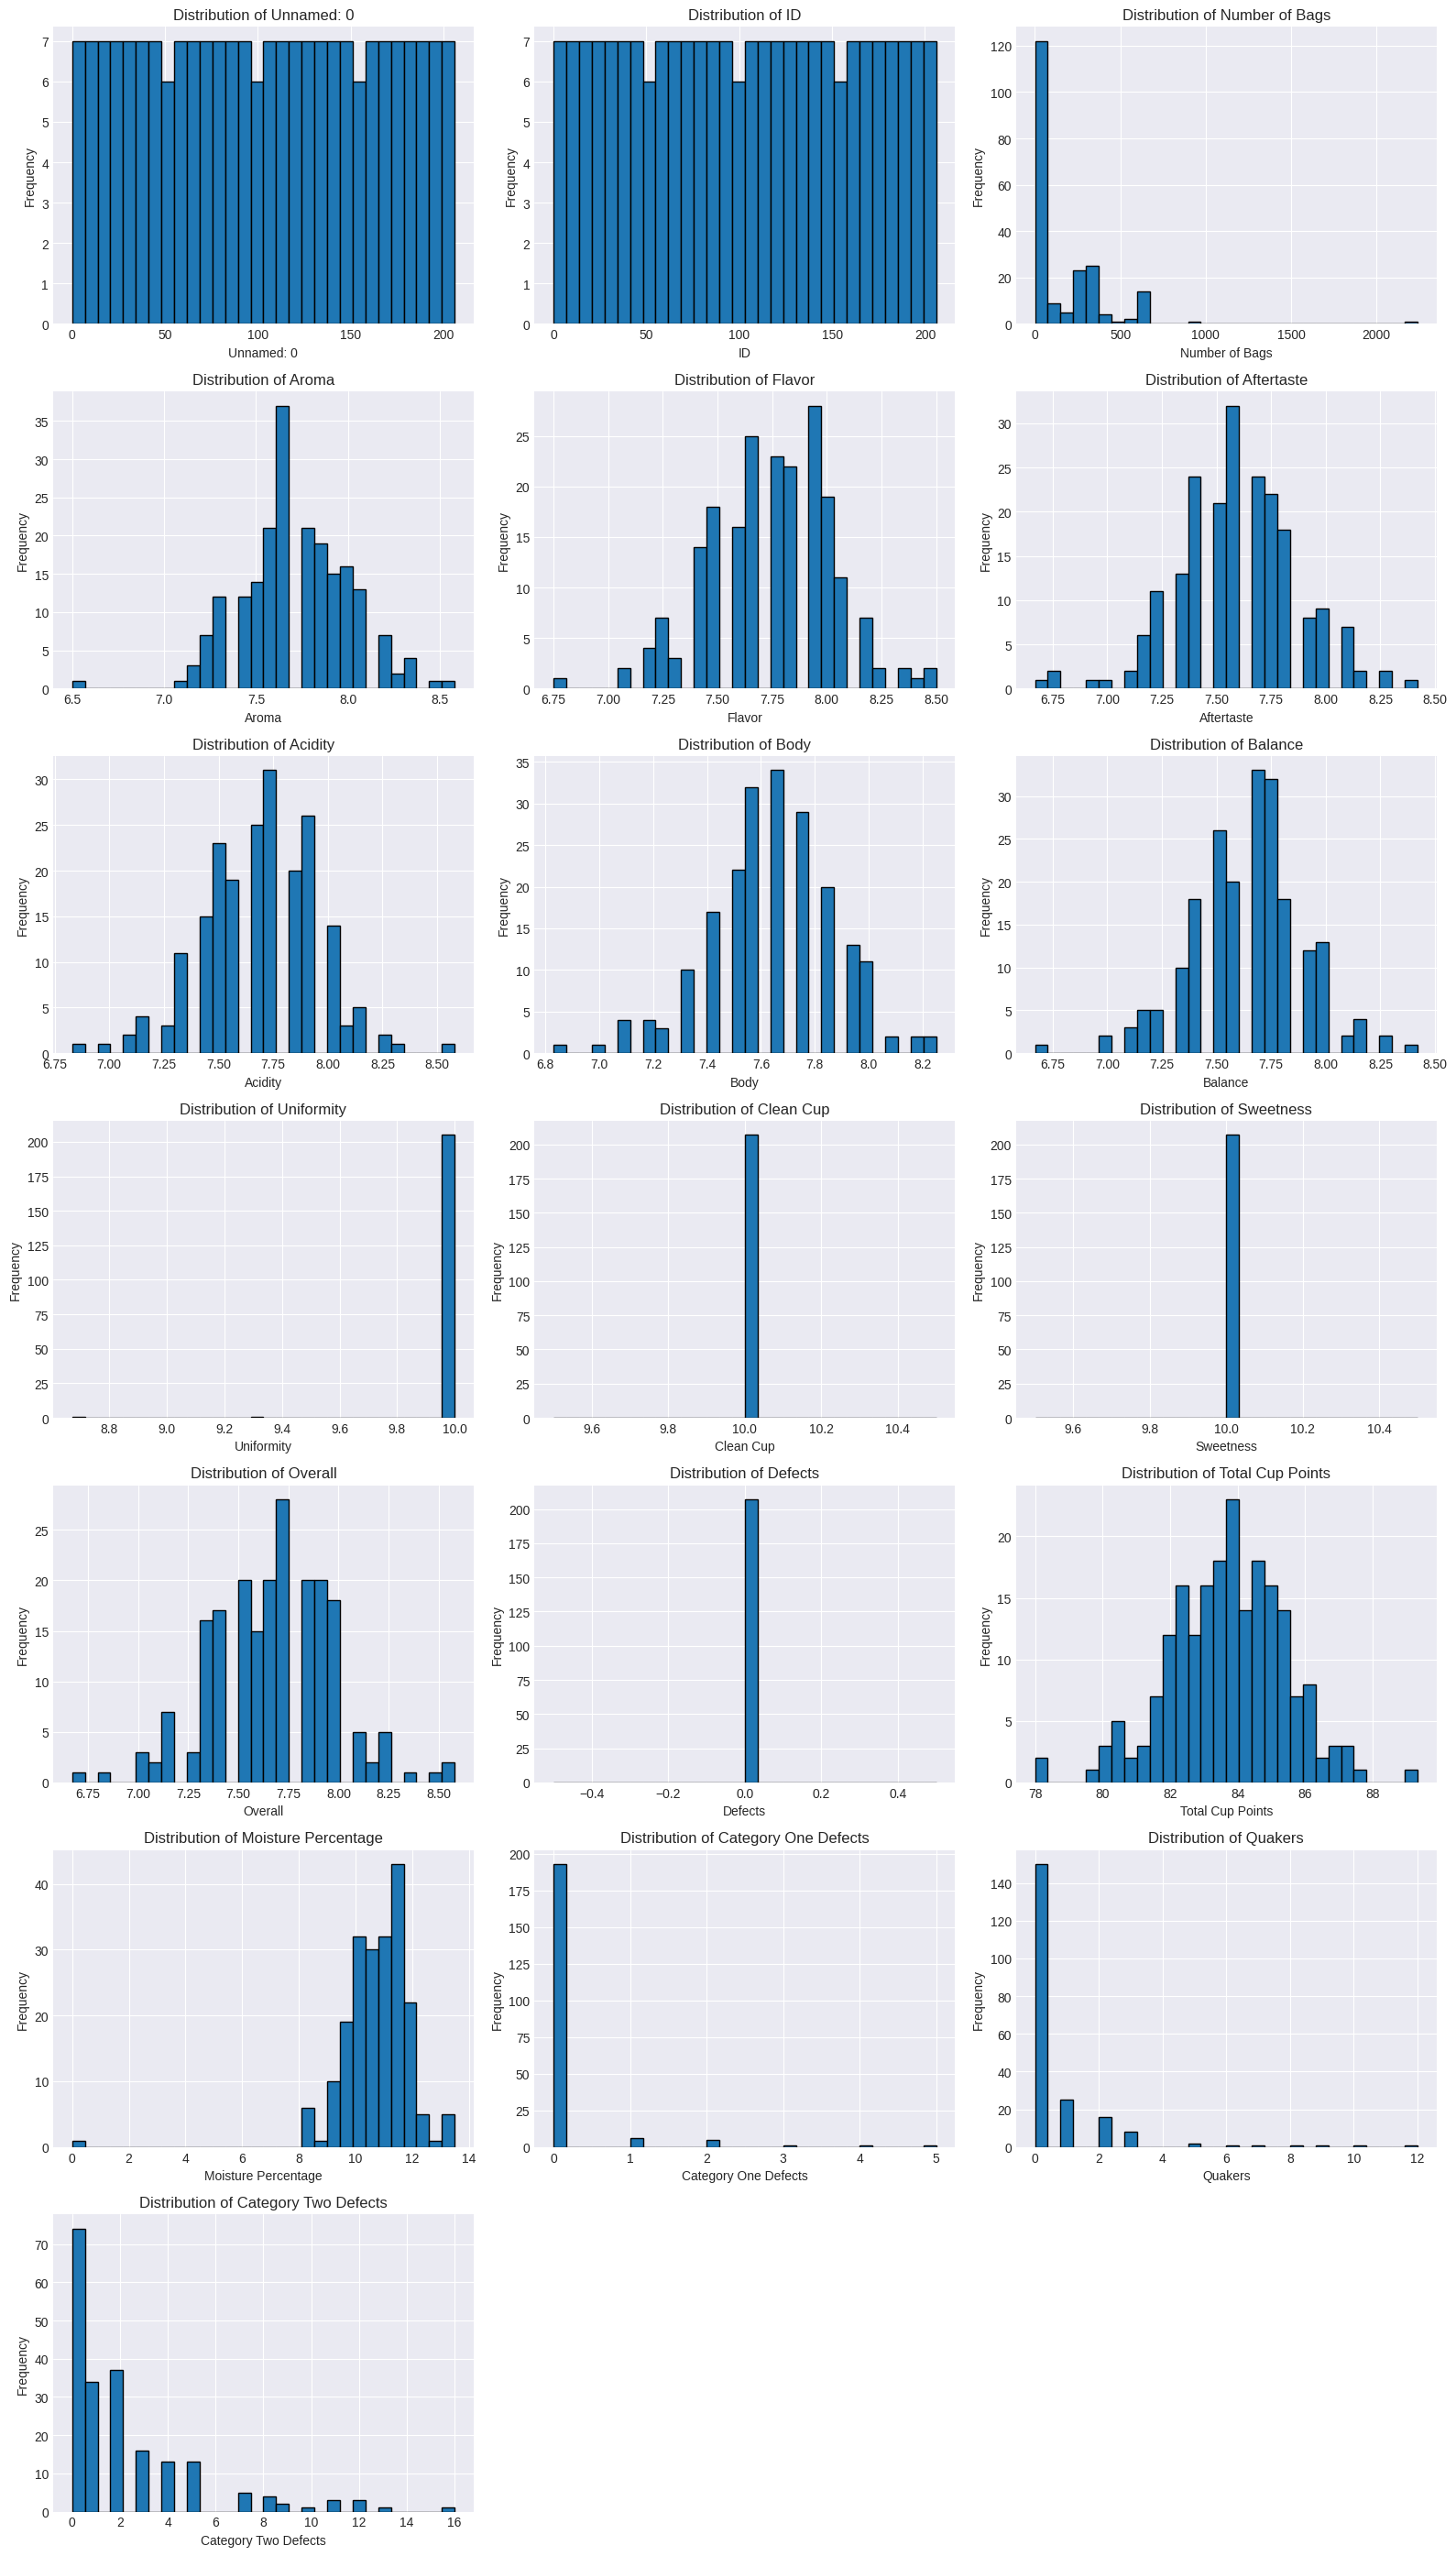

In [11]:
# Histograms for all numeric columns
if numeric_cols:
    n_cols = 3
    n_rows = int(np.ceil(len(numeric_cols) / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    for i, col in enumerate(numeric_cols):
        axes[i].hist(df_clean[col].dropna(), bins=30, edgecolor="black")
        axes[i].set_title(f"Distribution of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Frequency")

    for j in range(len(numeric_cols), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns available for histograms.")

## 8. Outlier Analysis

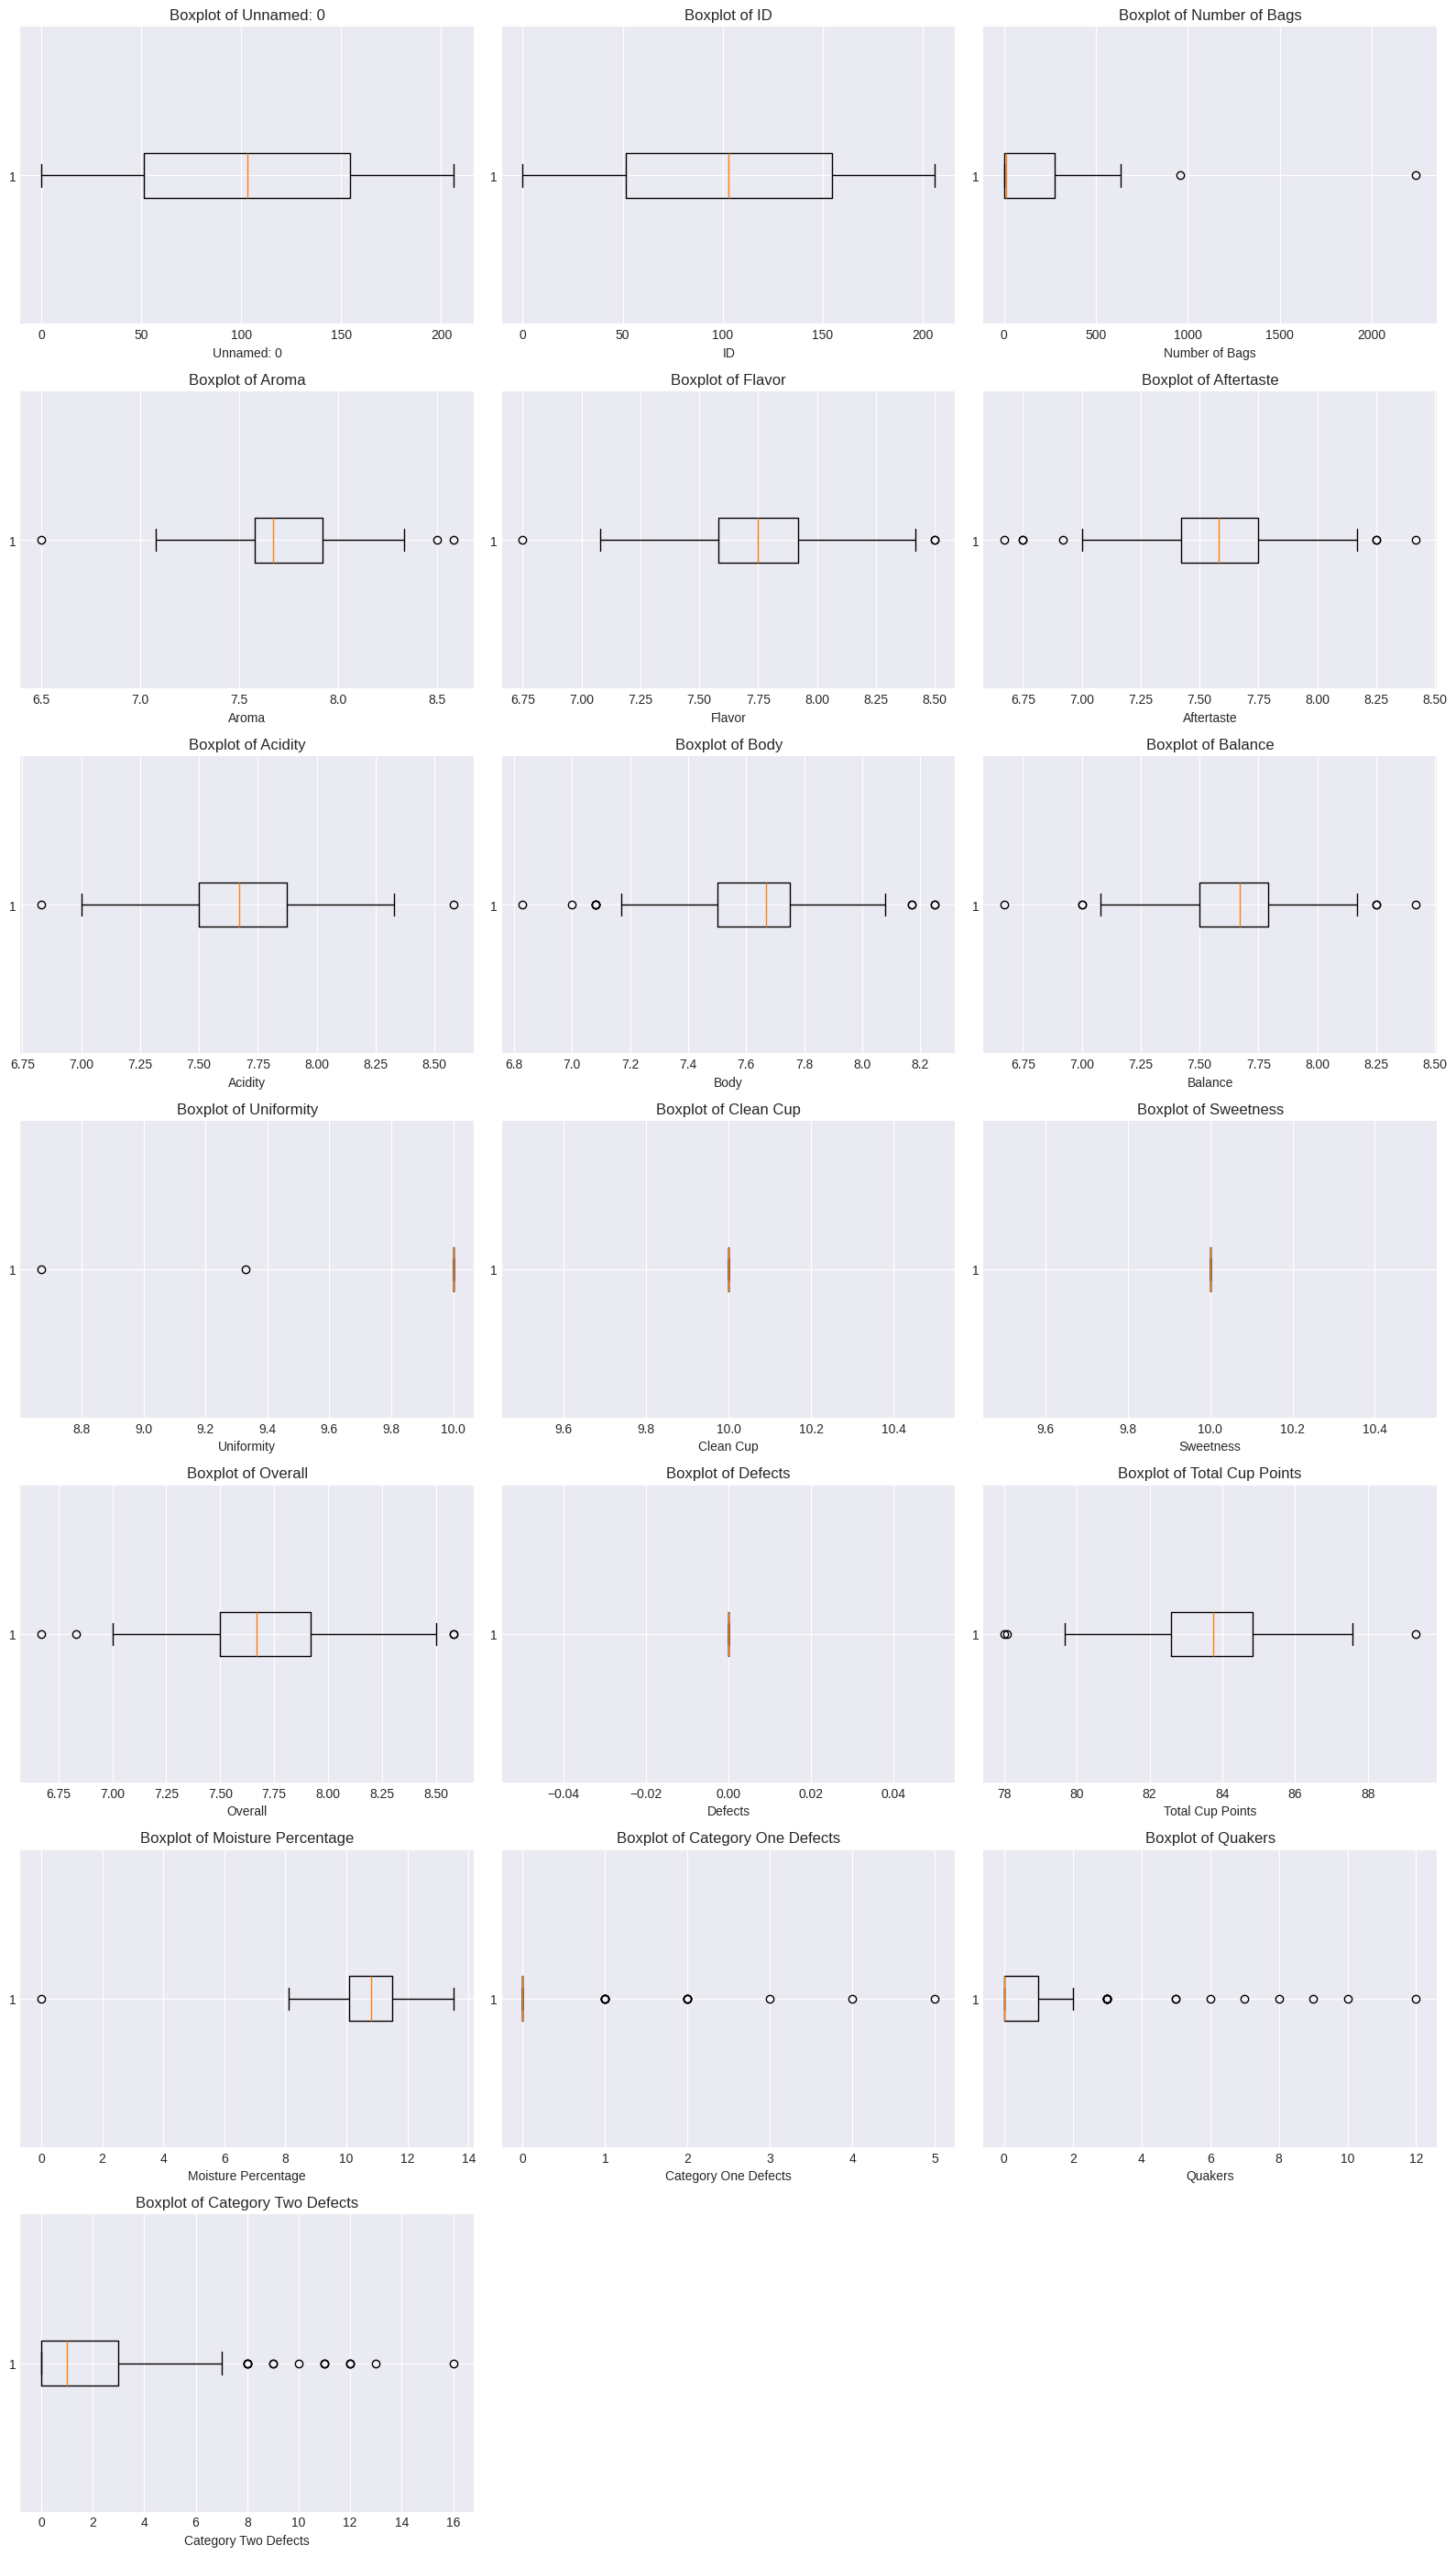

In [12]:
# Boxplots for numerical columns
if numeric_cols:
    n_cols = 3
    n_rows = int(np.ceil(len(numeric_cols) / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    for i, col in enumerate(numeric_cols):
        axes[i].boxplot(df_clean[col].dropna(), vert=False)
        axes[i].set_title(f"Boxplot of {col}")
        axes[i].set_xlabel(col)

    for j in range(len(numeric_cols), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns available for boxplots.")

In [13]:
# IQR-based outlier counts
outlier_summary = []

for col in numeric_cols:
    series = df_clean[col].dropna()

    if len(series) == 0:
        continue

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((series < lower) | (series > upper)).sum()

    outlier_summary.append({
        "column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(count),
        "outlier_percentage": round(100 * count / len(series), 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df.sort_values("outlier_count", ascending=False))

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
17,Quakers,0.00,1.000,1.000,-1.5000,2.5000,16,7.73
18,Category Two Defects,0.00,3.000,3.000,-4.5000,7.5000,15,7.25
16,Category One Defects,0.00,0.000,0.000,0.0000,0.0000,14,6.76
7,Body,7.50,7.750,0.250,7.1250,8.1250,10,4.83
5,Aftertaste,7.42,7.750,0.330,6.9250,8.2450,7,3.38
8,Balance,7.50,7.790,0.290,7.0650,8.2250,6,2.90
12,Overall,7.50,7.920,0.420,6.8700,8.5500,4,1.93
14,Total Cup Points,82.58,84.830,2.250,79.2050,88.2050,3,1.45
4,Flavor,7.58,7.920,0.340,7.0700,8.4300,3,1.45
3,Aroma,7.58,7.920,0.340,7.0700,8.4300,3,1.45


## 9. Categorical Variable Distributions

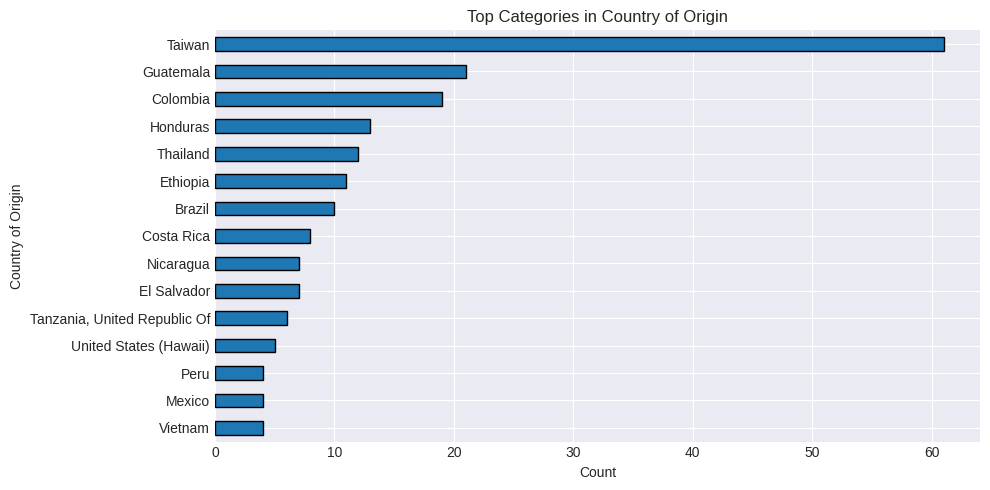

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 30343 (\N{CJK UNIFIED IDEOGRAPH-7687}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 24237 (\N{CJK UNIFIED IDEOGRAPH-5EAD}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21654 (\N{CJK UNIFIED IDEOGRAPH-5496}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21857 (\N{CJK UNIFIED IDEOGRAPH-5561}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 33674 (\N{CJK UNIFIED IDEOGRAPH-838A}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 22290 (\N{CJK UNIFIED IDEOGRAPH-5712}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 27704 (\N{CJK UNIFIE

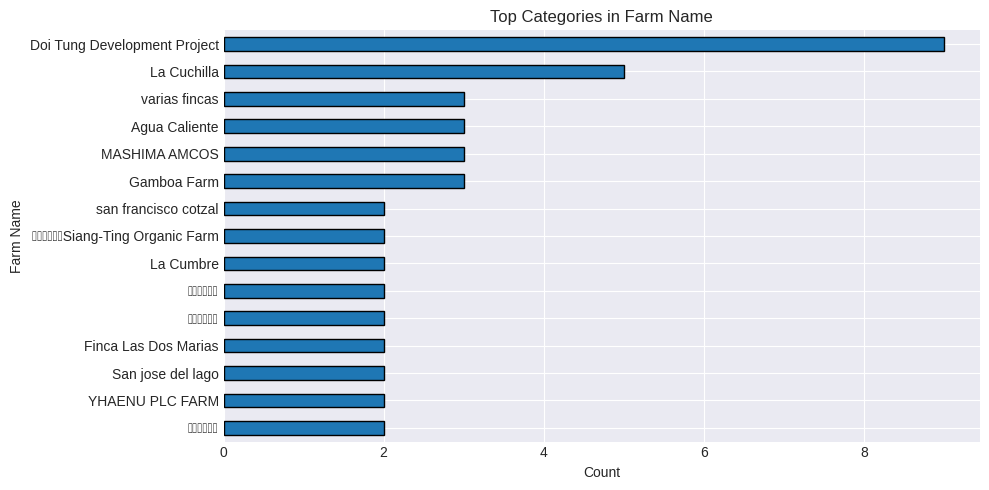

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 33274 (\N{CJK UNIFIED IDEOGRAPH-81FA}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21335 (\N{CJK UNIFIED IDEOGRAPH-5357}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 24066 (\N{CJK UNIFIED IDEOGRAPH-5E02}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 31934 (\N{CJK UNIFIED IDEOGRAPH-7CBE}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21697 (\N{CJK UNIFIED IDEOGRAPH-54C1}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21654 (\N{CJK UNIFIED IDEOGRAPH-5496}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21857 (\N{CJK UNIFIE

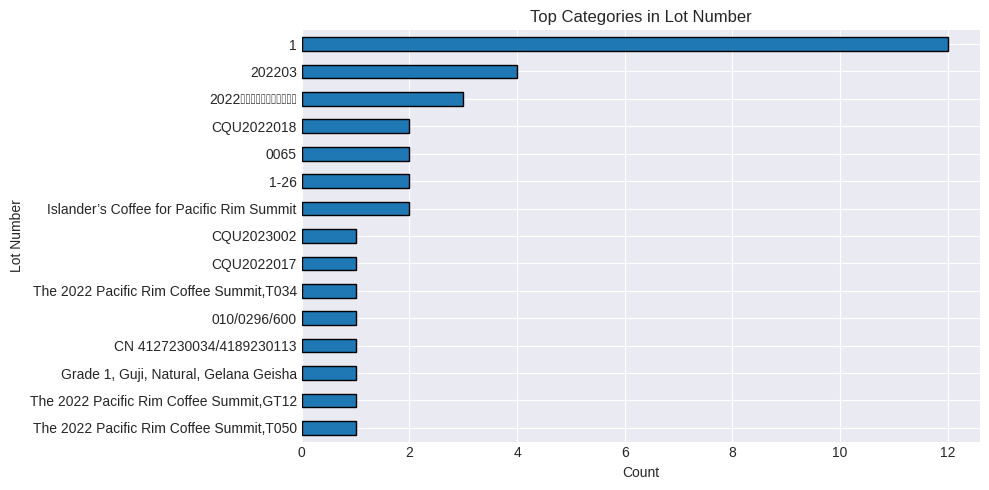

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 20094 (\N{CJK UNIFIED IDEOGRAPH-4E7E}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 29157 (\N{CJK UNIFIED IDEOGRAPH-71E5}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 27231 (\N{CJK UNIFIED IDEOGRAPH-6A5F}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 12289 (\N{IDEOGRAPHIC COMMA}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 33067 (\N{CJK UNIFIED IDEOGRAPH-812B}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 27580 (\N{CJK UNIFIED IDEOGRAPH-6BBC}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 37129 (\N{CJK UNIFIED IDEOGRA

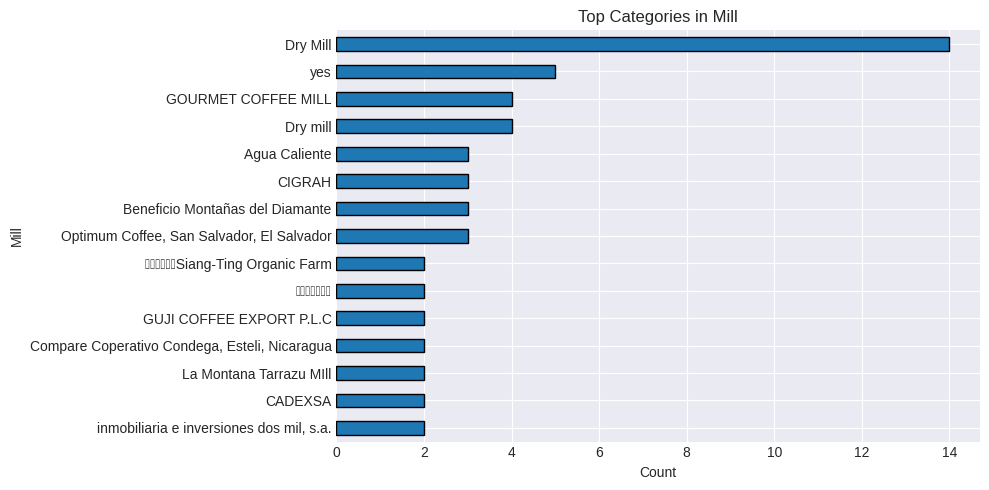

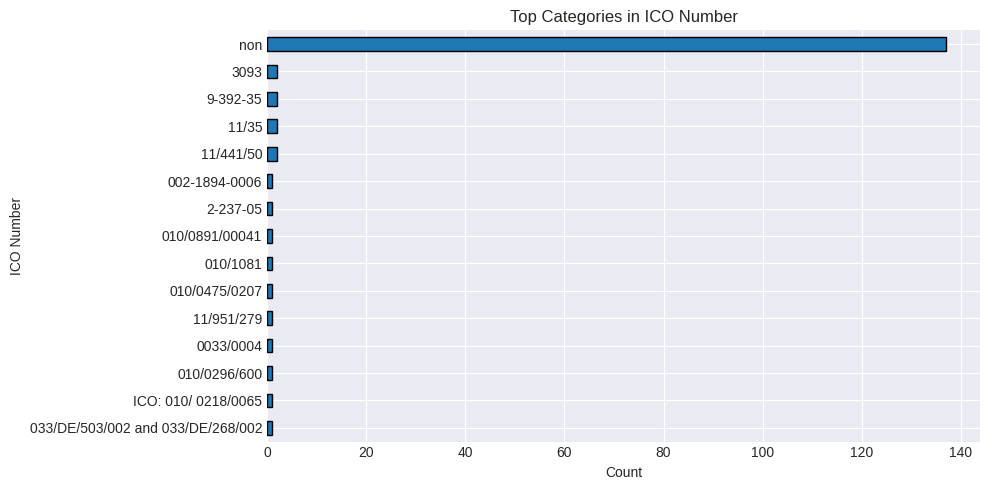

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 23480 (\N{CJK UNIFIED IDEOGRAPH-5BB8}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 23975 (\N{CJK UNIFIED IDEOGRAPH-5DA7}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 22283 (\N{CJK UNIFIED IDEOGRAPH-570B}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 38555 (\N{CJK UNIFIED IDEOGRAPH-969B}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 26377 (\N{CJK UNIFIED IDEOGRAPH-6709}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 38480 (\N{CJK UNIFIED IDEOGRAPH-9650}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 20844 (\N{CJK UNIFIE

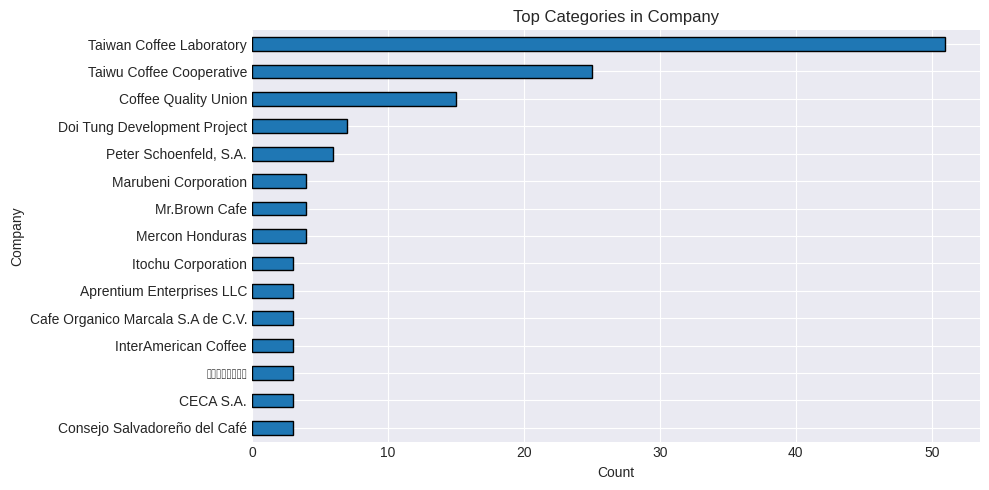

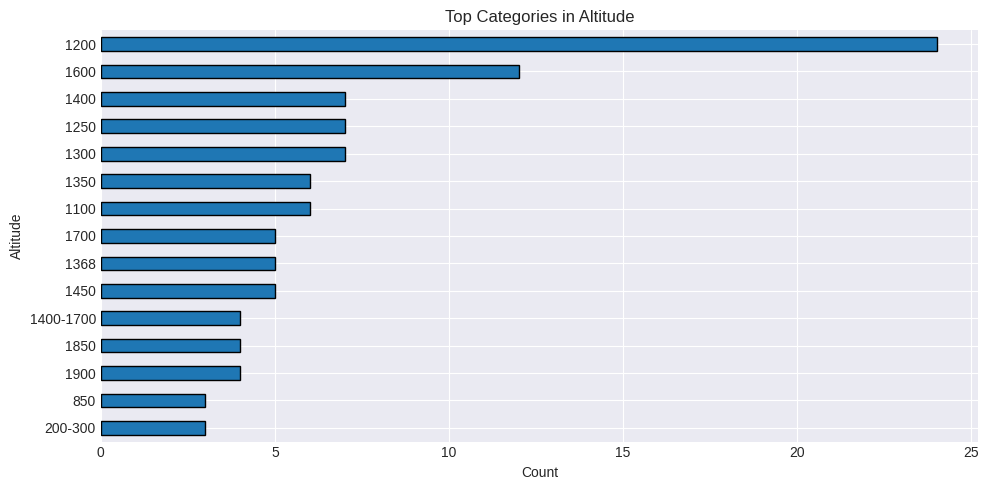

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 22781 (\N{CJK UNIFIED IDEOGRAPH-58FD}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 35920 (\N{CJK UNIFIED IDEOGRAPH-8C50}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 37129 (\N{CJK UNIFIED IDEOGRAPH-9109}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 26691 (\N{CJK UNIFIED IDEOGRAPH-6843}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 22290 (\N{CJK UNIFIED IDEOGRAPH-5712}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 24066 (\N{CJK UNIFIED IDEOGRAPH-5E02}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 33495 (\N{CJK UNIFIE

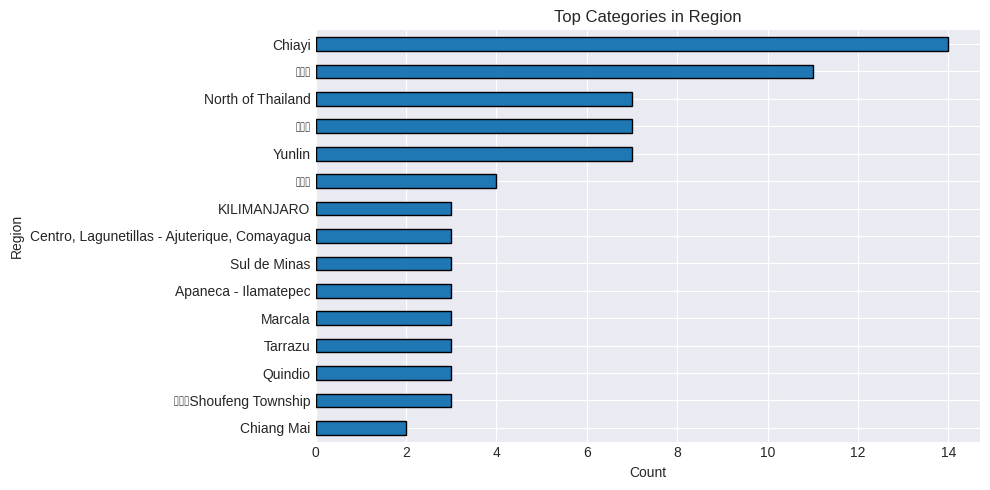

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 24373 (\N{CJK UNIFIED IDEOGRAPH-5F35}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 36914 (\N{CJK UNIFIED IDEOGRAPH-9032}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 32681 (\N{CJK UNIFIED IDEOGRAPH-7FA9}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 34311 (\N{CJK UNIFIED IDEOGRAPH-8607}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 29976 (\N{CJK UNIFIED IDEOGRAPH-7518}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 27704 (\N{CJK UNIFIED IDEOGRAPH-6C38}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: User

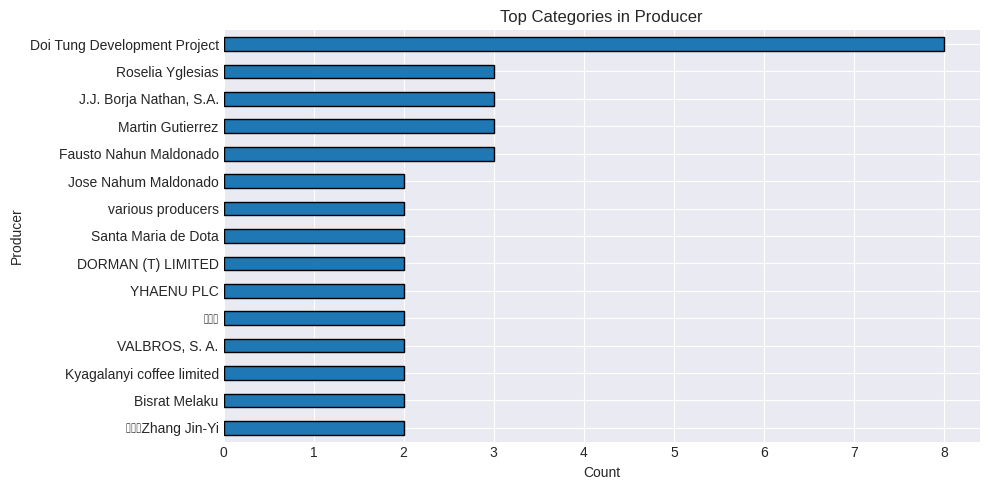

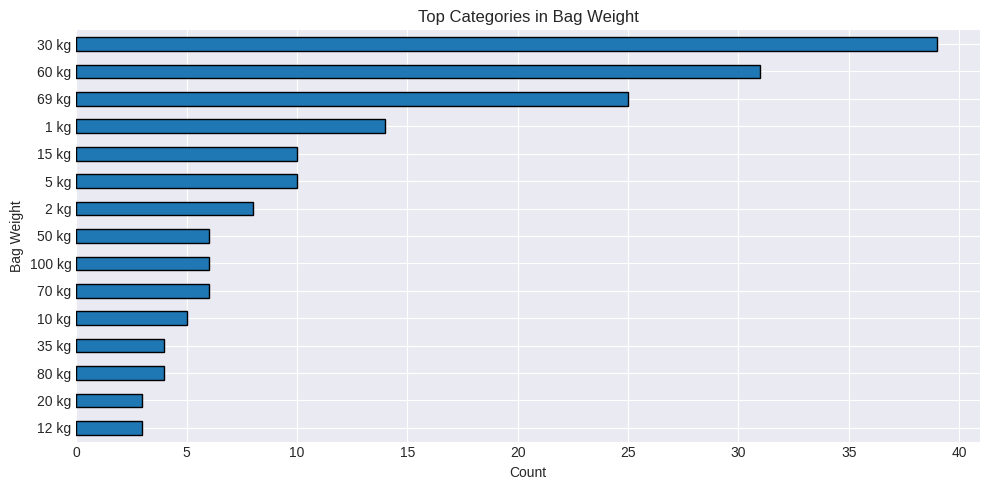

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 23480 (\N{CJK UNIFIED IDEOGRAPH-5BB8}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 23975 (\N{CJK UNIFIED IDEOGRAPH-5DA7}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 22283 (\N{CJK UNIFIED IDEOGRAPH-570B}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 38555 (\N{CJK UNIFIED IDEOGRAPH-969B}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21488 (\N{CJK UNIFIED IDEOGRAPH-53F0}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 28771 (\N{CJK UNIFIED IDEOGRAPH-7063}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21654 (\N{CJK UNIFIE

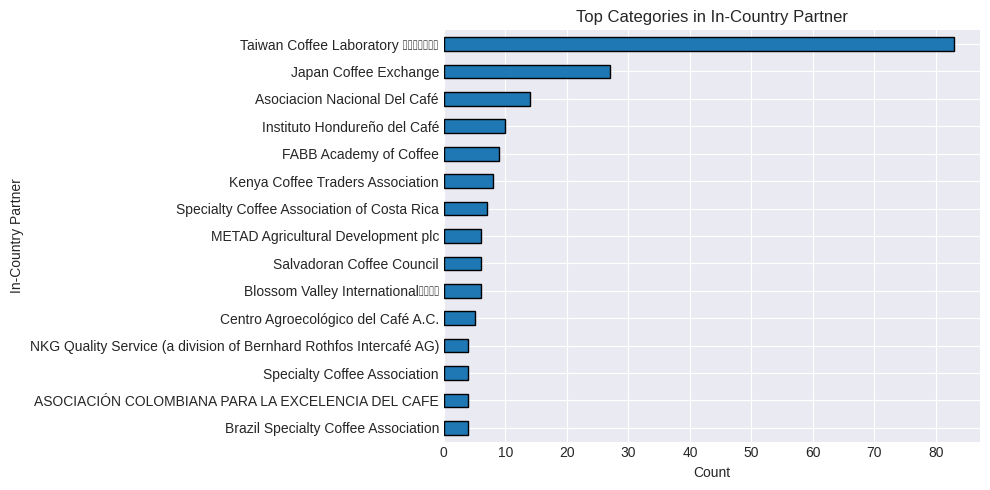

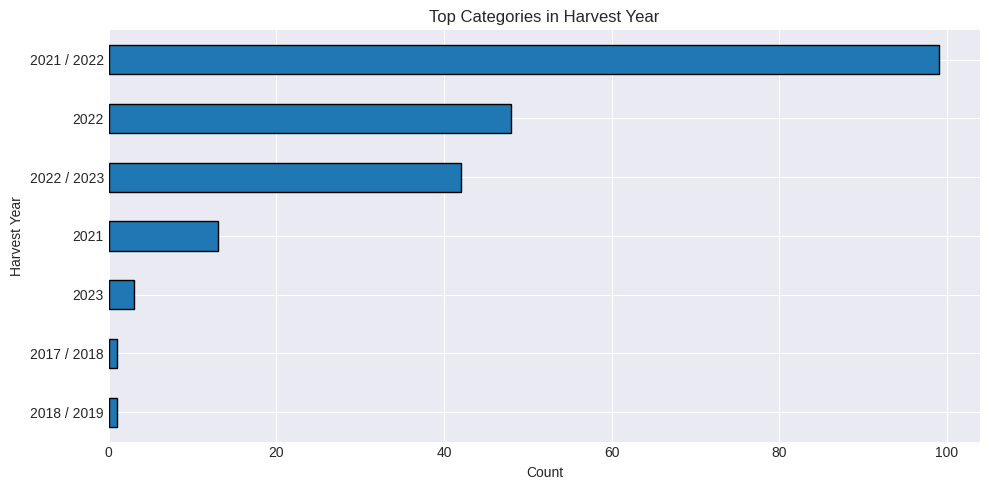

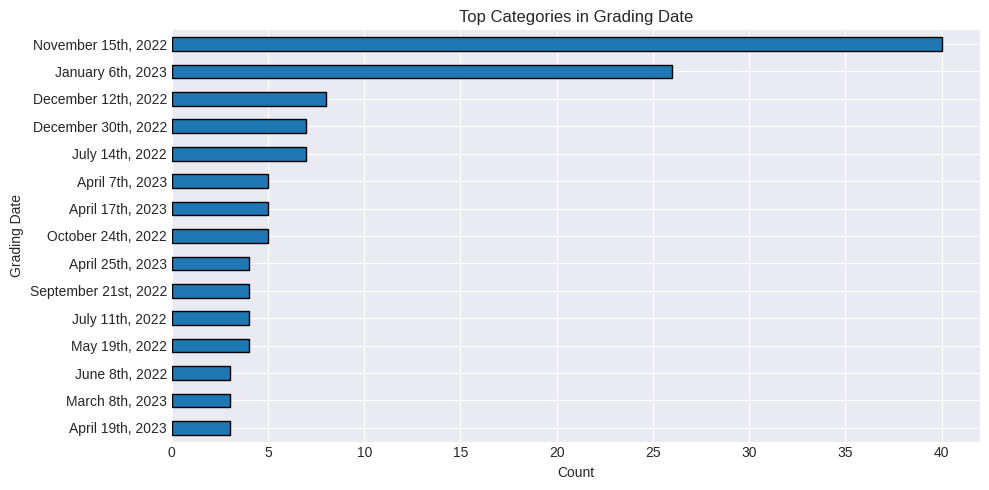

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21488 (\N{CJK UNIFIED IDEOGRAPH-53F0}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 28771 (\N{CJK UNIFIED IDEOGRAPH-7063}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21654 (\N{CJK UNIFIED IDEOGRAPH-5496}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21857 (\N{CJK UNIFIED IDEOGRAPH-5561}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 30740 (\N{CJK UNIFIED IDEOGRAPH-7814}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 31350 (\N{CJK UNIFIED IDEOGRAPH-7A76}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 23460 (\N{CJK UNIFIE

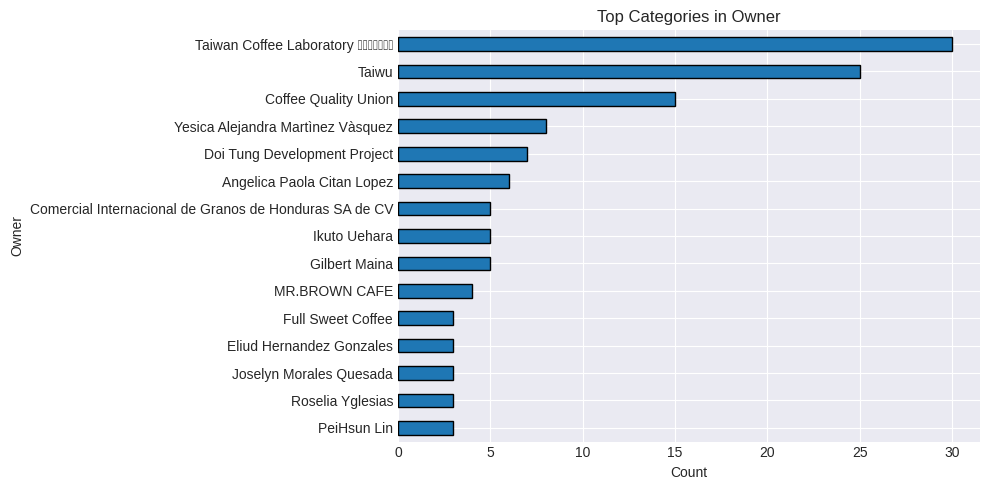

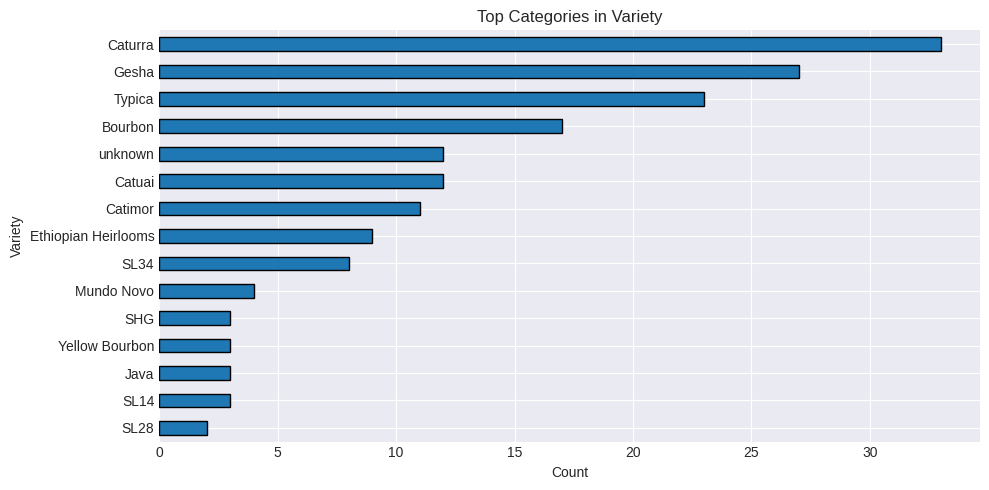

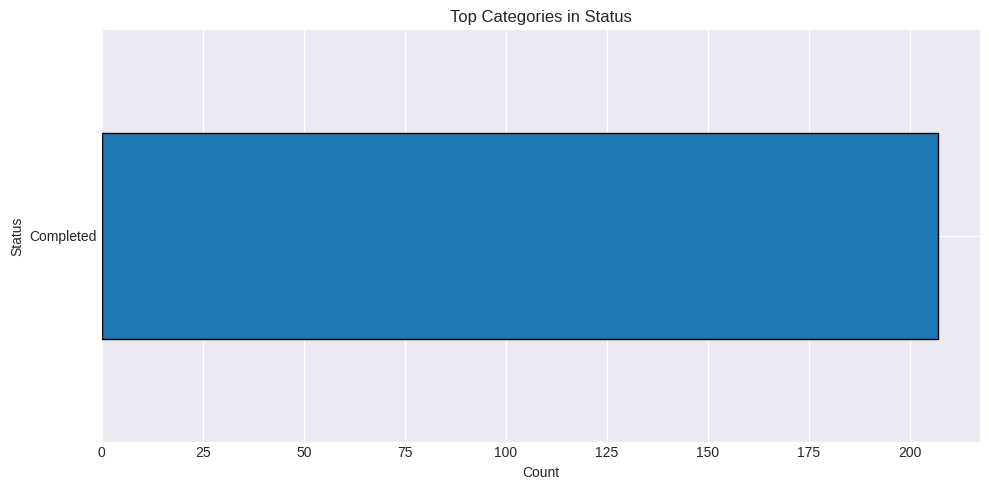

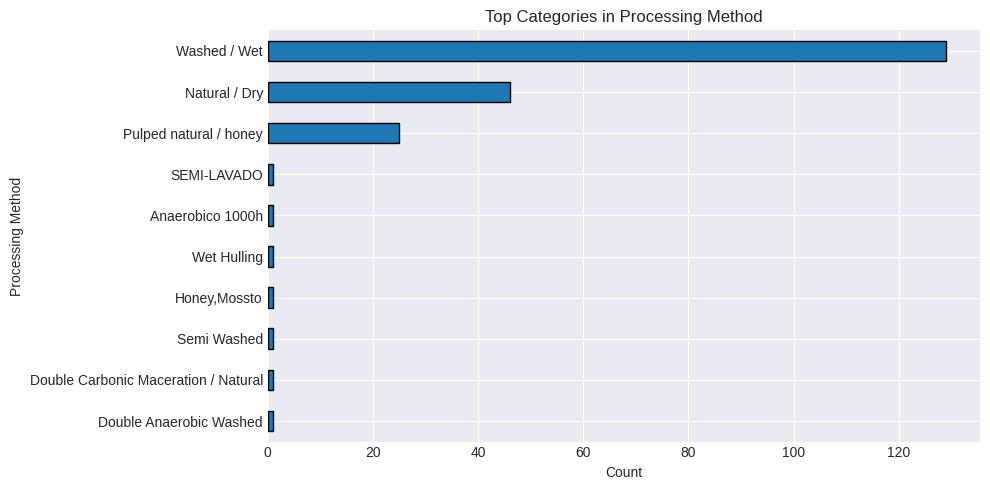

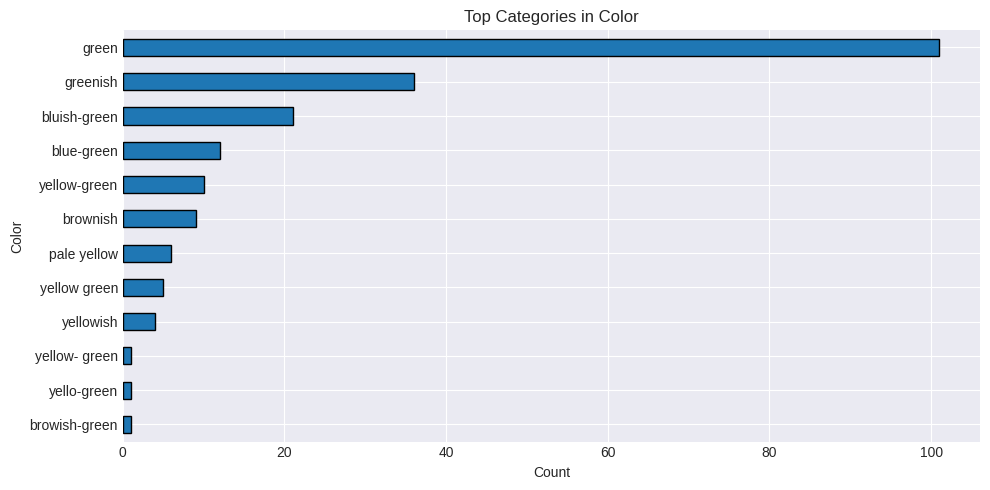

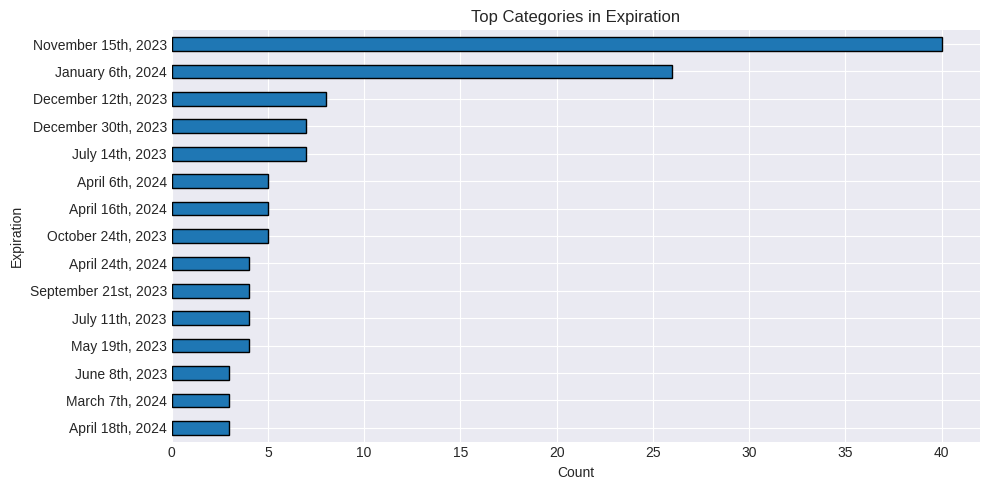

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 23480 (\N{CJK UNIFIED IDEOGRAPH-5BB8}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 23975 (\N{CJK UNIFIED IDEOGRAPH-5DA7}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 22283 (\N{CJK UNIFIED IDEOGRAPH-570B}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 38555 (\N{CJK UNIFIED IDEOGRAPH-969B}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21488 (\N{CJK UNIFIED IDEOGRAPH-53F0}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 28771 (\N{CJK UNIFIED IDEOGRAPH-7063}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 21654 (\N{CJK UNIFIE

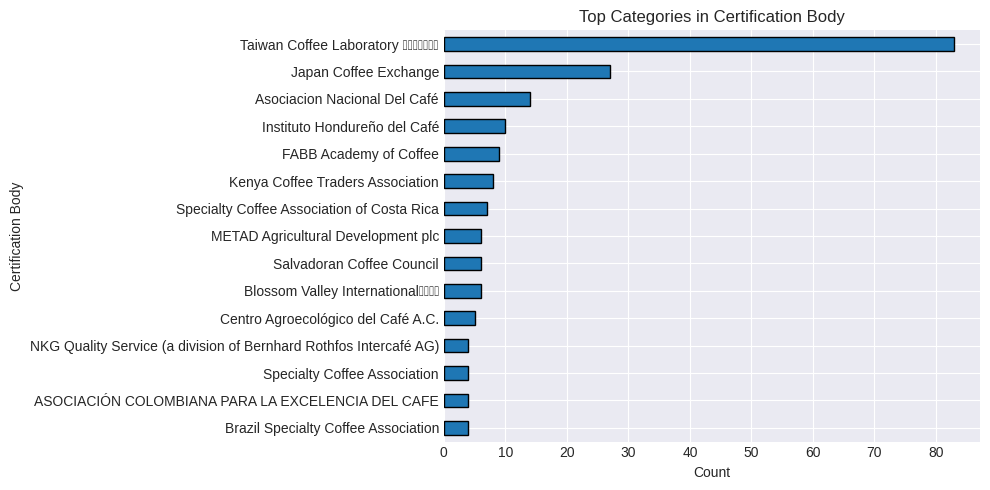

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 12306 (\N{POSTAL MARK}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 38745 (\N{CJK UNIFIED IDEOGRAPH-9759}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 23713 (\N{CJK UNIFIED IDEOGRAPH-5CA1}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 30476 (\N{CJK UNIFIED IDEOGRAPH-770C}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 29105 (\N{CJK UNIFIED IDEOGRAPH-71B1}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 28023 (\N{CJK UNIFIED IDEOGRAPH-6D77}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 24066 (\N{CJK UNIFIED IDEOGRAPH-5E0

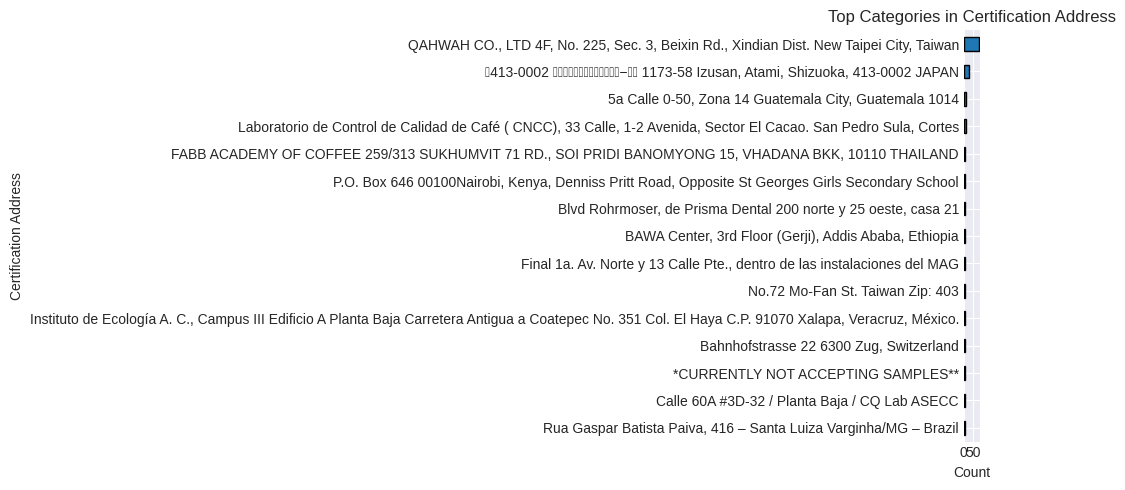

/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 38515 (\N{CJK UNIFIED IDEOGRAPH-9673}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 22025 (\N{CJK UNIFIED IDEOGRAPH-5609}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 23803 (\N{CJK UNIFIED IDEOGRAPH-5CFB}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 26494 (\N{CJK UNIFIED IDEOGRAPH-677E}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 28580 (\N{CJK UNIFIED IDEOGRAPH-6FA4}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 12288 (\N{IDEOGRAPHIC SPACE}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_4228/166767197.py:11: UserWarning: Glyph 23439 (\N{CJK UNIFIED IDEOGRA

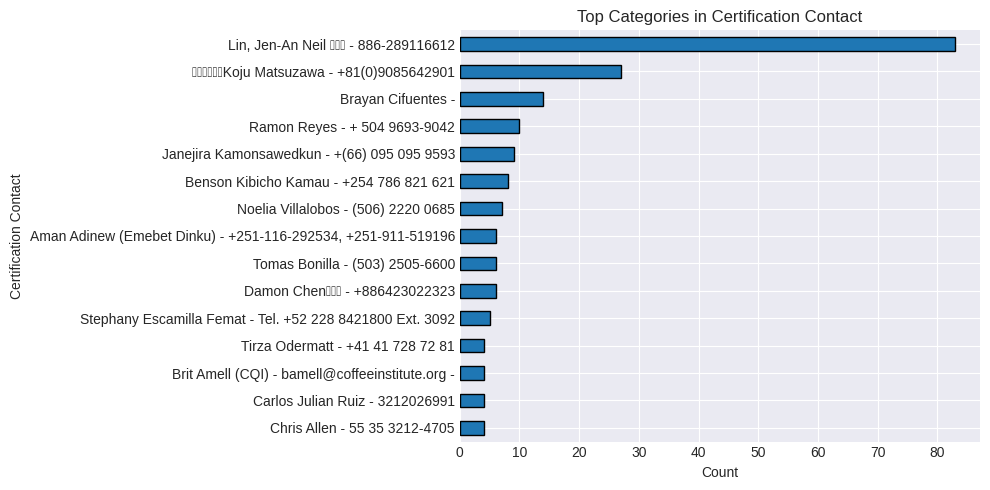

In [14]:
# Plot the most useful categorical variables.
# High-cardinality identifier/text fields are limited to their top 15 values.
for col in categorical_cols:
    counts = df_clean[col].value_counts().head(15)

    plt.figure(figsize=(10, 5))
    counts.sort_values().plot(kind="barh", edgecolor="black")
    plt.title(f"Top Categories in {col}")
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## 10. Correlation Analysis

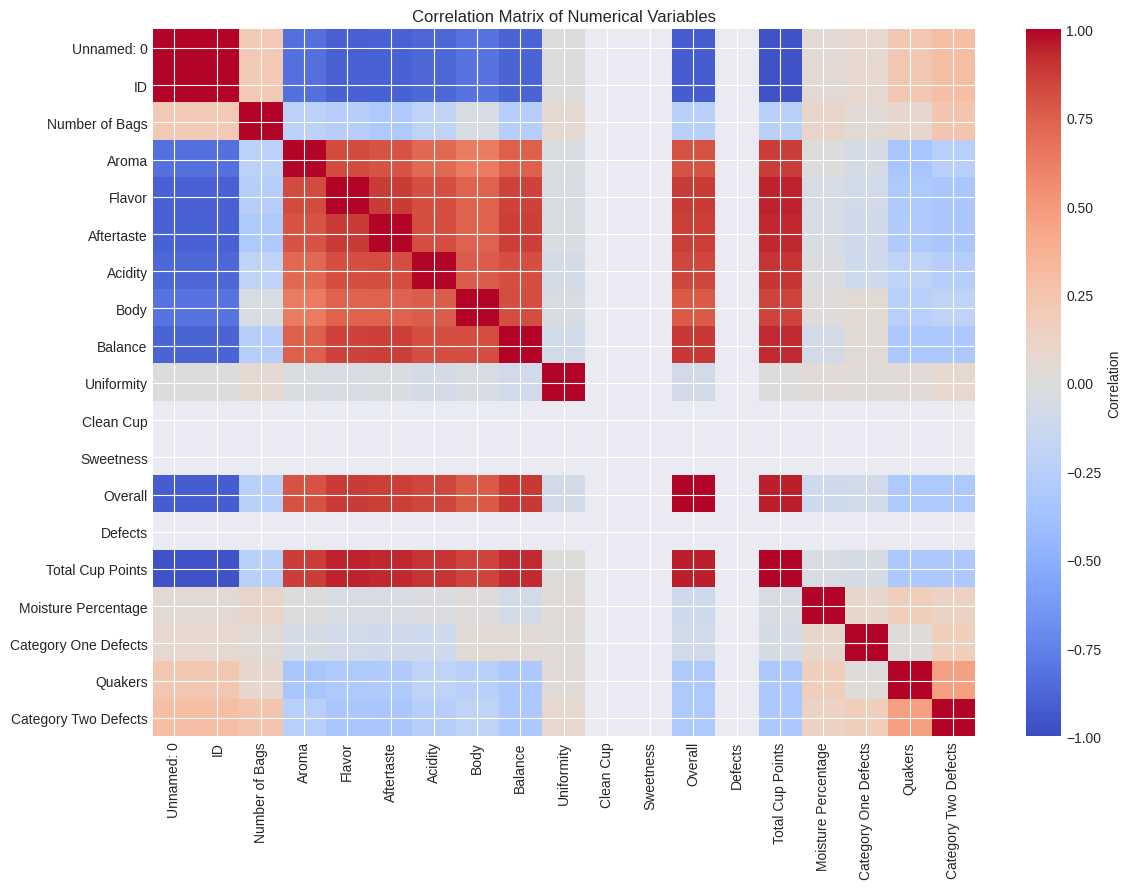

,Unnamed: 0,ID,Number of Bags,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean Cup,Sweetness,Overall,Defects,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Category Two Defects
Unnamed: 0,1.00,1.00,0.21,-0.83,-0.91,-0.90,-0.87,-0.82,-0.89,-0.01,NaN,NaN,-0.92,NaN,-0.96,0.05,0.07,0.23,0.28
ID,1.00,1.00,0.21,-0.83,-0.91,-0.90,-0.87,-0.82,-0.89,-0.01,NaN,NaN,-0.92,NaN,-0.96,0.05,0.07,0.23,0.28
Number of Bags,0.21,0.21,1.00,-0.23,-0.26,-0.30,-0.20,-0.04,-0.26,0.06,NaN,NaN,-0.24,NaN,-0.24,0.10,0.04,0.08,0.24
Aroma,-0.83,-0.83,-0.23,1.00,0.82,0.79,0.71,0.63,0.75,-0.03,NaN,NaN,0.80,NaN,0.87,-0.00,-0.06,-0.34,-0.25
Flavor,-0.91,-0.91,-0.26,0.82,1.00,0.88,0.81,0.74,0.85,-0.04,NaN,NaN,0.88,NaN,0.94,-0.05,-0.08,-0.31,-0.33
Aftertaste,-0.90,-0.90,-0.30,0.79,0.88,1.00,0.81,0.74,0.86,-0.02,NaN,NaN,0.87,NaN,0.93,-0.05,-0.11,-0.30,-0.33
Acidity,-0.87,-0.87,-0.20,0.71,0.81,0.81,1.00,0.77,0.81,-0.06,NaN,NaN,0.84,NaN,0.90,-0.02,-0.11,-0.21,-0.26
Body,-0.82,-0.82,-0.04,0.63,0.74,0.74,0.77,1.00,0.82,-0.04,NaN,NaN,0.77,NaN,0.85,0.01,0.05,-0.26,-0.21
Balance,-0.89,-0.89,-0.26,0.75,0.85,0.86,0.81,0.82,1.00,-0.09,NaN,NaN,0.88,NaN,0.93,-0.07,0.04,-0.32,-0.32
Uniformity,-0.01,-0.01,0.06,-0.03,-0.04,-0.02,-0.06,-0.04,-0.09,1.00,NaN,NaN,-0.07,NaN,0.00,0.04,0.02,0.04,0.07


In [15]:
if len(numeric_cols) >= 2:
    corr = df_clean[numeric_cols].corr()

    plt.figure(figsize=(12, 9))
    plt.imshow(corr, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
    plt.colorbar(label="Correlation")

    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)

    plt.title("Correlation Matrix of Numerical Variables")
    plt.tight_layout()
    plt.show()

    display(corr.round(2))
else:
    print("At least two numeric columns are required for correlation analysis.")

In [16]:
# List the strongest absolute correlations between different numerical variables
if len(numeric_cols) >= 2:
    corr = df_clean[numeric_cols].corr()

    pairs = []
    for i in range(len(corr.columns)):
        for j in range(i + 1, len(corr.columns)):
            pairs.append({
                "variable_1": corr.columns[i],
                "variable_2": corr.columns[j],
                "correlation": corr.iloc[i, j],
                "absolute_correlation": abs(corr.iloc[i, j])
            })

    strongest = pd.DataFrame(pairs).sort_values(
        "absolute_correlation", ascending=False
    ).head(10)

    print("Strongest numerical correlations:")
    display(strongest)

Strongest numerical correlations:


,variable_1,variable_2,correlation,absolute_correlation
0,Unnamed: 0,ID,1.000000,1.000000
13,Unnamed: 0,Total Cup Points,-0.963143,0.963143
30,ID,Total Cup Points,-0.963143,0.963143
151,Overall,Total Cup Points,0.947217,0.947217
75,Flavor,Total Cup Points,0.939124,0.939124
88,Aftertaste,Total Cup Points,0.934813,0.934813
121,Balance,Total Cup Points,0.929520,0.929520
11,Unnamed: 0,Overall,-0.918025,0.918025
28,ID,Overall,-0.918025,0.918025
20,ID,Flavor,-0.905225,0.905225


## 11. Key Observations

In [17]:
print("EDA completed successfully.")
print()
print("Dataset shape after cleaning:", df_clean.shape)
print("Number of numerical variables:", len(numeric_cols))
print("Number of categorical variables:", len(categorical_cols))
print("Remaining missing values:", int(df_clean.isnull().sum().sum()))

if len(numeric_cols) >= 2:
    corr = df_clean[numeric_cols].corr()
    corr_pairs = []

    for i in range(len(corr.columns)):
        for j in range(i + 1, len(corr.columns)):
            corr_pairs.append((abs(corr.iloc[i, j]), corr.columns[i], corr.columns[j], corr.iloc[i, j]))

    corr_pairs.sort(reverse=True)

    if corr_pairs:
        strongest = corr_pairs[0]
        print(
            f"Strongest numerical correlation: {strongest[1]} vs {strongest[2]} "
            f"(r = {strongest[3]:.3f})"
        )

print("\nThe plots and statistics above can be used to discuss:")
print("- the central tendency and spread of the numerical variables,")
print("- skewness and unusual observations visible in the distributions,")
print("- potential outliers identified by the boxplots,")
print("- dominant categories in categorical variables, and")
print("- relationships between numerical coffee-quality attributes.")

EDA completed successfully.

Dataset shape after cleaning: (207, 41)
Number of numerical variables: 19
Number of categorical variables: 22
Remaining missing values: 0
Strongest numerical correlation: Unnamed: 0 vs ID (r = 1.000)

The plots and statistics above can be used to discuss:
- the central tendency and spread of the numerical variables,
- skewness and unusual observations visible in the distributions,
- potential outliers identified by the boxplots,
- dominant categories in categorical variables, and
- relationships between numerical coffee-quality attributes.
